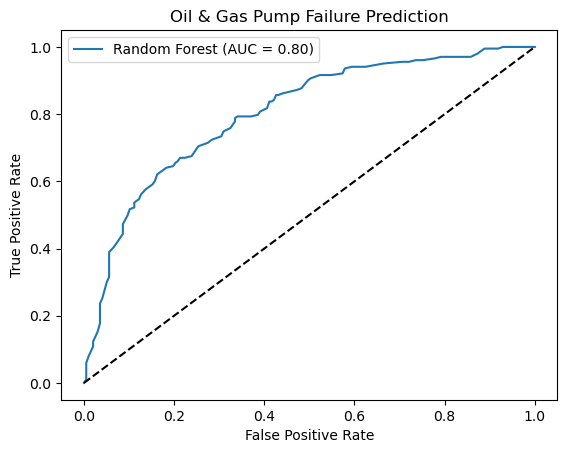

ROC-AUC: 0.802
Failure rate in simulated data: 0.508


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Generate illustrative synthetic plant data
np.random.seed(42)
n = 2000

df = pd.DataFrame({
    "temperature_c": np.random.normal(75, 12, n),
    "vibration_mm_s": np.random.normal(4, 1.5, n),
    "pressure_bar": np.random.normal(20, 3, n),
    "flow_rate_m3_h": np.random.normal(100, 15, n),
    "operating_hours": np.random.randint(100, 20000, n)
})

# 2. Simulate failure labels for learning purposes
risk_score = (
    0.08 * (df["temperature_c"] - 75)
    + 0.8 * (df["vibration_mm_s"] - 4)
    - 0.025 * (df["flow_rate_m3_h"] - 100)
    + 0.00003 * (df["operating_hours"] - 10000)
)

probability = 1 / (1 + np.exp(-risk_score))
df["failure_within_24h"] = (
    np.random.random(n) < probability
).astype(int)

# 3. Separate features and target
X = df.drop(columns="failure_within_24h")
y = df["failure_within_24h"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Train the model
model = RandomForestClassifier(
    n_estimators=100, random_state=42,
    class_weight="balanced"
)
model.fit(X_train, y_train)

# 5. Predict failure probabilities
y_pred_probs = model.predict_proba(X_test)[:, 1]

# 6. Evaluate the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_probs)
auc = roc_auc_score(y_test, y_pred_probs)

plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Oil & Gas Pump Failure Prediction")
plt.legend()
plt.show()

print("ROC-AUC:", round(auc, 3))
print("Failure rate in simulated data:", round(y.mean(), 3))


In [2]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

# Predict classes using the default threshold of 0.5
y_pred = model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[137  60]
 [ 54 149]]
              precision    recall  f1-score   support

           0       0.72      0.70      0.71       197
           1       0.71      0.73      0.72       203

    accuracy                           0.71       400
   macro avg       0.72      0.71      0.71       400
weighted avg       0.72      0.71      0.71       400

